# Lorenz-96 with linear observations

Lorenz-96, $d = 40$, $N_e = 20$, every 4th variable observed directly ($25\,\%$ coverage),
$\sigma_{\rm obs} = 0.1$, analyses every $\Delta t_{\rm obs} = 0.2$. In the standard
Lorenz-96 scaling one time unit is five days, so this is a 24-hour cycle and
$\Delta t_{\rm obs}$ is half the model's error-doubling time of $0.42$. The initial ensemble
is the truth plus $0.5\,\mathcal{N}(0, I)$. Forty cycles are run and cycles 10-39 are scored.
Hyperparameters were tuned on seeds 100-104 and the methods are scored on seeds 0-9.

| method | analysis |
|---|---|
| LETKF | Gaussian ensemble transform, domain-localized |
| RML-3DVar | randomized maximum likelihood, closed form, same localized $\mathbf{C}$ as CI-EnSF |
| CI-EnSF | covariance-shaped diffusion |

For a given seed all three share the truth trajectory, the observation network, the
observation-noise realization, the ensemble size and the initial ensemble. A run is a failure
if it becomes non-finite (*overflow*) or if its scored RMSE exceeds half the climatological
standard deviation (*filter divergence*).

**Produces** Table 1 and Figure 1 of the manuscript. The selected hyperparameters are
hard-coded in section 6; no sweep is re-run. Set `RUN_SIMULATION = False` to rebuild the
table and the figure from `gaussian24h_cache.npz`.

## 1. Configuration

In [1]:
import numpy as np, time, json
import matplotlib
import matplotlib.pyplot as plt

# ---------------- model
D            = 40          # state dimension
F_FORCING    = 8.0         # Lorenz-96 forcing
DT_TRUTH     = 0.01        # integration step for the truth
DT_MODEL     = 0.02        # integration step for the forecast model (deliberately coarser)
DT_OBS       = 0.2         # analysis interval.  L96 at F=8 has a doubling time of 0.42,
                           # so this is half a doubling time -- the standard setting.
SPINUP_STEPS = 2000        # steps to reach the attractor before the truth run starts

# ---------------- observations
OBS_STRIDE   = 4           # observe every 4th variable -> 25 % coverage
SIGMA_OBS    = 0.1         # observation error standard deviation

# ---------------- ensemble
K            = 20          # ensemble members
SIGMA_INIT   = 0.5         # initial ensemble = truth + SIGMA_INIT * N(0, I), NOT re-centred

# ---------------- experiment
N_CYCLES     = 40
SCORE_SKIP   = 0.25        # discard the first quarter before scoring
EVAL_SEEDS   = tuple(range(10))
EPS_C        = 1e-6        # ridge added to B before its eigendecomposition
STD_FLOOR    = 1e-8

obs_idx  = np.arange(0, D, OBS_STRIDE)
obs_mask = np.zeros(D, bool); obs_mask[obs_idx] = True
Q        = obs_idx.size
R_DIAG   = np.full(Q, SIGMA_OBS**2)


### Recomputation switch

`RUN_SIMULATION = False` rebuilds the table and the figure from `gaussian24h_cache.npz`
without running a filter. The cache is written whenever `RUN_SIMULATION = True`.

In [2]:
import os, json
RUN_SIMULATION = False         # False -> load exp1_cache.npz and only redraw
CACHE = "gaussian24h_cache.npz"

def save_cache(**kw):
    # compressed: the JSON payloads are stored by numpy as UTF-32, four bytes per
    # character, so an uncompressed cache is several times larger than it needs to be.
    np.savez_compressed(CACHE, **{k: (v if isinstance(v, np.ndarray) else np.array(json.dumps(v)))
                                  for k, v in kw.items()})

def load_cache():
    z = np.load(CACHE, allow_pickle=False)
    return {k: (json.loads(str(z[k])) if z[k].dtype.kind in "US" else z[k]) for k in z.files}

if not RUN_SIMULATION and not os.path.exists(CACHE):
    raise SystemExit("RUN_SIMULATION = False but %s is missing; run once with True." % CACHE)

## 2. Model and observation operator

Lorenz-96, $\dot x_i = (x_{i+1}-x_{i-2})x_{i-1} - x_i + F$, integrated with RK4.

In [3]:
def l96_rhs(x):
    return (np.roll(x, -1, -1) - np.roll(x, 2, -1))*np.roll(x, 1, -1) - x + F_FORCING

def rk4(x, dt, steps):
    for _ in range(steps):
        k1 = l96_rhs(x); k2 = l96_rhs(x + 0.5*dt*k1)
        k3 = l96_rhs(x + 0.5*dt*k2); k4 = l96_rhs(x + dt*k3)
        x = x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)
    return x

M_op     = lambda v: v          # direct observation
M_prime  = lambda v: np.ones_like(v)

def make_truth(seed, n_cycles):
    """Truth trajectory and initial ensemble.  The rng is returned and reused so that the
    observation noise and every filter's own draws come from ONE stream per seed."""
    rng = np.random.default_rng(seed)
    x = rk4(rng.normal(scale=3.0, size=D), DT_TRUTH, SPINUP_STEPS)
    T = np.empty((n_cycles, D))
    for n in range(n_cycles):
        T[n] = x
        x = rk4(x, DT_TRUTH, int(round(DT_OBS/DT_TRUTH)))
    X0 = T[0] + SIGMA_INIT*rng.standard_normal((K, D))
    return T, X0, rng

# The climatological standard deviation sets the filter-divergence threshold, so it is
# measured here rather than hard-coded: a 400-cycle truth run of the model.
_T, _, _ = make_truth(0, 400)
CLIM_STD  = float(_T.std())
FAIL_RMSE = 0.5*CLIM_STD        # filter-divergence threshold

## 3. Localization and the background-error covariance

Notation follows the manuscript. $\mathbf{C}$ is the localized correlation matrix of the
standardized ensemble, Eq. (17):

$$\mathbf{C} = \frac{1}{1+\varepsilon}\Big[\mathbf{C}_{\rm loc}\circ
\frac{\mathbf{A}\mathbf{A}^\top}{N_e-1} + \varepsilon\mathbf{I}\Big],
\qquad \varepsilon = 10^{-6},$$

with $\mathbf{A}$ the matrix of standardized anomalies, so $\mathbf{C}$ has unit diagonal.
The physical-space covariance of Eq. (19) is $\mathbf{B}^f = \mathbf{D}\mathbf{C}\mathbf{D}$
with $\mathbf{D} = \mathrm{diag}(\sigma^f)$. In the code these are `Cm` and `Bf`.

$\mathbf{C}_{\rm loc}$ here is the **indicator** of the Gaspari-Cohn support, 1 inside and 0
outside, with the half-support convention: $\rho_{\rm GC}(r/L)$ is zero for $r \ge 2L$, so
`L_loc` is a scale and the support ends at $2\,$`L_loc`. An indicator taper is not positive
semidefinite — its smallest eigenvalue is about $-2.4$ at $L = 3$ — so $\varepsilon$ alone
does not make $\mathbf{C}$ usable and `build_C` clips the eigenvalues at zero. The SQG
experiments use Gaspari-Cohn values instead, which are positive semidefinite.

RML-3DVar and CI-EnSF build the same $\mathbf{C}$.

In [4]:
def rho_gc(rr):
    """Gaspari-Cohn, compactly supported on rr < 2."""
    rr = np.abs(np.asarray(rr, float)); out = np.zeros_like(rr)
    n = rr <= 1; x = rr[n]; out[n] = 1 - (5/3)*x**2 + (5/8)*x**3 + 0.5*x**4 - 0.25*x**5
    f = (rr > 1) & (rr < 2); x = rr[f]
    out[f] = 4 - 5*x + (5/3)*x**2 + (5/8)*x**3 - 0.5*x**4 + x**5/12 - 2/(3*x)
    return out

DIST = np.minimum(np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]),
                  D - np.abs(np.arange(D)[:,None] - np.arange(D)[None,:]))

_TAPER = {}
def taper_matrix(L_loc):
    """Indicator taper at scale L_loc (support ends at 2*L_loc)."""
    key = float(L_loc)
    if key not in _TAPER:
        _TAPER[key] = (rho_gc(DIST/float(L_loc)) > 0).astype(float)
    return _TAPER[key]

def build_C(U, L_loc):
    """Localized correlation of the standardized ensemble U (K, d), and a square root.

    The eigenvalue clip is not optional: running the transport with the raw, unclipped
    Schur product loses every seed within a few cycles, because the indicator taper is not
    positive semidefinite (its smallest eigenvalue is about -2.4 at L_loc = 3)."""
    A  = U - U.mean(0)
    P  = taper_matrix(L_loc)*((A.T @ A)/(K - 1))
    Cm = (P + EPS_C*np.eye(D))/(1.0 + EPS_C)
    lam, QB = np.linalg.eigh(0.5*(Cm + Cm.T))
    lam = np.maximum(lam, 0.0)
    return (QB*lam) @ QB.T, QB*np.sqrt(lam)

def standardize(Xf):
    shift = Xf.mean(0)
    std   = np.maximum(Xf.std(0, ddof=1), STD_FLOOR)
    return shift, std, (Xf - shift)/std


## 4. The three analysis schemes

All three have the signature `analyze(Xf, y, rng, **hyper) -> Xa`, both `(K, d)` in physical
units, so the cycling driver is shared.

### 4.1 LETKF
Ensemble transform solved in the $K$-dimensional ensemble subspace with domain localization:
for each grid point $j$, observations inside the GC support of $j$ are assimilated, weighted
by $\rho_{\rm GC}$. No explicit $d\times d$ covariance is formed.

In [5]:
def letkf(Xf, y, rng, L_loc=3.0, inflation=1.0, **_):
    xbar = Xf.mean(0); Xb = Xf - xbar
    if inflation != 1.0: Xb = Xb*inflation
    hx = M_op(Xf[:, obs_idx] if inflation == 1.0 else (xbar + Xb)[:, obs_idx])
    Yb = hx - hx.mean(0); d = y - hx.mean(0)
    Xa = np.empty_like(Xf)
    for j in range(D):
        w = rho_gc(DIST[j, obs_idx]/L_loc)
        sel = w > 0
        if not sel.any(): Xa[:, j] = xbar[j] + Xb[:, j]; continue
        Yl = Yb[:, sel]; inv = w[sel]/R_DIAG[sel]
        A = (K - 1)*np.eye(K) + (Yl*inv) @ Yl.T
        lam, Qm = np.linalg.eigh(0.5*(A + A.T)); lam = np.maximum(lam, 1e-12)
        Pa = (Qm/lam) @ Qm.T
        wa = Pa @ ((Yl*inv) @ d[sel])
        W  = (Qm*np.sqrt((K - 1)/lam)) @ Qm.T
        Xa[:, j] = xbar[j] + Xb[:, j] @ (wa[:, None] + W)
    return Xa

### 4.2 RML-3DVar (ensemble 3D-Var)

Each member solves its own randomized variational problem. The cost is quadratic here, so
the solution is closed form:
$$\mathbf{x}^{a,k} = \mathbf{x}^{k} + \gamma\mathbf{B}^f\mathbf{H}^\top
(\gamma\mathbf{H}\mathbf{B}^f\mathbf{H}^\top + \mathbf{R})^{-1}(\mathbf{y}^k - \mathbf{H}\mathbf{x}^k),
\qquad \mathbf{y}^k = \mathbf{y} + \boldsymbol\varepsilon^k .$$
$\gamma$ is tuned rather than fixed at the value the RML derivation gives.

In [6]:
def rml_3dvar(Xf, y, rng, gamma=1.0, L_loc=3.0, **_):
    shift, std, U = standardize(Xf)
    Cm, _ = build_C(U, L_loc)
    Bf  = (std[:, None]*Cm)*std[None, :]          # correlation -> physical covariance
    Bf_oo = Bf[np.ix_(obs_idx, obs_idx)]; Bf_xo = Bf[:, obs_idx]
    S   = gamma*Bf_oo + np.diag(R_DIAG)
    yk  = y + rng.normal(scale=np.sqrt(R_DIAG), size=(K, Q))
    W   = np.linalg.solve(S, (yk - M_op(Xf[:, obs_idx])).T).T
    return Xf + gamma*(W @ Bf_xo.T)

### 4.3 CI-EnSF

Conditioned on the standardized member $\mathbf{u}_i$ the transition kernel is Eq. (26),
$$\mathbf{z}_t \mid \mathbf{u}_i \sim
\mathcal{N}\big((1-t)\mathbf{u}_i,\ c(t)\mathbf{C}\big),\qquad c(t) = (1-t)^2\gamma + t,$$
so the covariance stays a scalar multiple of $\mathbf{C}$ and the covariance-weighted
forecast score is Eq. (30),
$$\mathbf{C}\,\mathbf{s}^f_{t,i}(\mathbf{z})
= -\frac{\mathbf{z} - (1-t)\mathbf{u}_i}{c(t)},$$
i.e. $\mathbf{C}$ cancels from the prior transport and is never solved with. It remains in
the likelihood transport of Eq. (37), weighted by $w(t) = 1-t$. Perturbed observations are
used, one set per member.

In [7]:
# --- the innovation-consistency controller for gamma -------------------------------------
# gamma sets the prior width; a FIXED gamma cannot react when the forecast ensemble becomes
# over- or under-confident relative to the actual innovations.  The controller below is to
# CI-EnSF what multiplicative inflation is to the LETKF -- part of the standard
# configuration, not an optional extra -- so it is exposed as a tuning option (`ctrl`)
# rather than left off.  It uses only y and the forecast, never the truth.
W_SMOOTH, P_GAIN = 0.3, 0.5
GAMMA_LO, GAMMA_HI = 0.05, 0.5

def innovation_ratio(Xf, y):
    """rho = sum d^2 / sum[(1 + 1/K) s_f^2 + r].  Target 1.  The (1 + 1/K) is the
    finite-ensemble correction; without it rho is biased high by 5 % at K = 20."""
    hx = M_op(Xf[:, obs_idx]); d = y - hx.mean(0)
    return float(d @ d / np.sum((1.0 + 1.0/K)*hx.var(0, ddof=1) + R_DIAG))

def update_gamma(gamma, rho_s, ctrl="on"):
    """on : gamma <- clip(gamma * rho_s**P_GAIN, GAMMA_LO, GAMMA_HI).  A single
            multiplicative response with no trigger threshold and no decay constant: the
            smoothed ratio rho_s is already the only quantity the controller needs, and
            rho_s < 1 shrinks gamma by the same law that rho_s > 1 grows it.
       off: no control, gamma stays at its initial value."""
    if ctrl == "off": return gamma
    return float(min(max(gamma*rho_s**P_GAIN, GAMMA_LO), GAMMA_HI))


def cvt_ensf(Xf, y, rng, gamma=0.1, L_loc=4.0, n_steps=400, t_stop=0.1, **_):
    shift, std, U = standardize(Xf)
    Cm, Lm = build_C(U, L_loc)
    off_o, std_o = shift[obs_idx], std[obs_idx]
    yk = y + rng.normal(scale=np.sqrt(R_DIAG), size=(K, Q))
    dt = (1.0 - t_stop)/n_steps
    z  = rng.standard_normal((K, D)) @ Lm.T     # terminal law N(0, B), not N(0, I)
    for n in range(n_steps):
        t  = 1.0 - (n + 1)*dt
        c  = (1.0 - t)**2*gamma + t
        bb = 1.0/(1.0 - t); s2 = (1.0 + t)/(1.0 - t)
        Cs = -(z - (1.0 - t)*U)/c               # B cancels here
        xs  = std_o*z[:, obs_idx] + off_o
        lik = np.zeros_like(z)
        lik[:, obs_idx] = -(std_o*M_prime(xs))*(M_op(xs) - yk)/R_DIAG
        Cs = Cs + (1.0 - t)*(lik @ Cm)          # B acts here, spreading information
        z  = z - dt*(-bb*z - 0.5*s2*Cs)
        if not np.isfinite(z).all():
            raise FloatingPointError("CI-EnSF diverged at step %d (t=%.4f)" % (n, t))
    return std*z + shift

METHODS = {"LETKF": letkf, "RML-3DVar": rml_3dvar, "CI-EnSF": cvt_ensf}

## 5. Cycling driver and scoring

Shared by all three methods. Overflow and filter divergence are recorded separately, and the
observed / unobserved error split is kept for every run.

In [8]:
def run_cycles(fn, kw, seed, n_cycles=N_CYCLES):
    """Returns (hist, status) with hist columns (rmse_obs, rmse_unobs, rmse_all, spread)."""
    T, X, rng = make_truth(seed, n_cycles)
    hist, status = [], "ok"
    kw = dict(kw); ctrl = kw.pop("ctrl", None)      # CI-EnSF only
    gamma, rho_s = kw.get("gamma", None), 1.0
    for n in range(n_cycles):
        y = M_op(T[n][obs_idx]) + rng.normal(scale=SIGMA_OBS, size=Q)
        if ctrl is not None and ctrl != "off":
            rho_s = (1 - W_SMOOTH)*rho_s + W_SMOOTH*innovation_ratio(X, y)
            gamma = update_gamma(gamma, rho_s, ctrl)
            kw["gamma"] = gamma
        try:
            X = fn(X, y, rng, **kw)
        except (FloatingPointError, np.linalg.LinAlgError):
            status = "overflow"; break
        e = X.mean(0) - T[n]
        hist.append((np.sqrt((e[obs_mask]**2).mean()), np.sqrt((e[~obs_mask]**2).mean()),
                     np.sqrt((e**2).mean()), float(np.sqrt(X.var(0, ddof=1).mean()))))
        X = rk4(X, DT_MODEL, int(round(DT_OBS/DT_MODEL)))
        if not np.isfinite(X).all(): status = "overflow"; break
    h = np.array(hist) if hist else np.zeros((0, 4))
    i0 = int(SCORE_SKIP*n_cycles)
    if status == "ok" and (len(h) < n_cycles or h[i0:, 2].mean() > FAIL_RMSE):
        status = "divergence"
    return h, status

def summarise(fn, kw, seeds, n_cycles=N_CYCLES):
    """Per-seed scores.  Values are kept for failed seeds too, and flagged, so that a method
    is never flattered by silently dropping the seeds it failed on."""
    out = []
    for s in seeds:
        h, st = run_cycles(fn, kw, s, n_cycles)
        i0 = int(SCORE_SKIP*n_cycles)
        if len(h) > i0:
            # spread/RMSE is aggregated in the SQUARE and only then divided: the
            # spread-skill identity E[spread^2] = (Ne/(Ne+1)) E[error^2] is a relation
            # between second moments, so sqrt(mean s^2)/sqrt(mean r^2) is what the
            # reference sqrt(Ne/(Ne+1)) applies to.  A mean of per-cycle ratios is biased
            # high -- on a synthetic ensemble calibrated by construction it returns 0.994
            # against the reference 0.976 at d = 40, and the bias depends on d, so the same
            # reference would not hold across the L96 and SQG experiments.
            out.append(dict(seed=s, status=st, hist=h.tolist(), rmse=h[i0:,2].mean(), obs=h[i0:,0].mean(),
                            unobs=h[i0:,1].mean(),
                            sprms=float(np.sqrt((h[i0:,3]**2).mean()
                                              / (h[i0:,2]**2).mean()))))
        else:
            out.append(dict(seed=s, status=st, hist=h.tolist(), rmse=np.inf, obs=np.inf, unobs=np.inf, sprms=np.nan))
    return out


## 6. Selected hyperparameters

Every value below is a literal, selected on seeds 100-104. The search is not re-run here.

| method | selected value |
|---|---|
| LETKF | $L = 14$, inflation $1.05$ |
| RML-3DVar | $\gamma = 1.5$, $L = 3$ |
| CI-EnSF | $\gamma_0 = 0.05$, $L = 4$, controller on |
| $\gamma$ controller | $w_{\rm EMA} = 0.3$, $p = 1/2$, $\gamma \in [0.05,\, 0.5]$ |
| localization ridge | $\varepsilon = 10^{-6}$ |

The controller update law is
$\gamma \leftarrow \mathrm{clip}(\gamma\,\rho_s^{1/2}, \gamma_{\rm lo}, \gamma_{\rm hi})$.

In [9]:
# Selected hyperparameters -- literals; section 6 says where each came from.  The gamma
# controller's own constants are hard-coded in section 4.3 and the localization ridge in
# section 1 (EPS_C = 1e-6).
TUNED = {"LETKF":     dict(L_loc=14.0, inflation=1.05),
         "RML-3DVar": dict(gamma=1.5,  L_loc=3.0),
         "CI-EnSF":   dict(gamma=0.05, L_loc=4.0, ctrl="on")}

## 7. The 10-seed evaluation run

Ten evaluation seeds (0-9), each method at the setting above: 40 analysis cycles from an
ensemble initialized at the truth plus $0.5\,\mathcal{N}(0, I)$, scored over cycles 10-39.

In [10]:
if RUN_SIMULATION:
    RESULTS = {}
    for name in METHODS:
        t0 = time.time()
        RESULTS[name] = summarise(METHODS[name], TUNED[name], EVAL_SEEDS)
        print("%-11s done  [%.0f s]" % (name, time.time() - t0))
else:
    RESULTS = load_cache()["results"]
    print("loaded %d methods from cache" % len(RESULTS))

def table(results):
    """Five metrics, in the same form as the arctan experiment so the two are comparable.

        survived      seeds completed without overflow or filter divergence
        RMSE (surv)   mean RMSE over the surviving seeds only
        sp/rms (surv) ensemble spread over RMSE, survivors only; the ideal value is
                      sqrt(K/(K+1)) = 0.976 for K = 20, not 1
        RMSE (all)    mean RMSE over every seed, failures included at their actual score
        worst         the single worst seed

    Nothing fails in this regime, so the two RMSE columns coincide and the survivor count is
    full.  That is the result: the same table under the arctan operator does not have that
    property, and the two are only comparable if they are built the same way.
    """
    rows = []
    for name, r in results.items():
        allr = np.array([x["rmse"] if np.isfinite(x["rmse"]) else FAIL_RMSE for x in r])
        ok   = [x for x in r if x["status"] == "ok"]
        rmo  = np.array([x["rmse"] for x in ok]) if ok else np.array([np.nan])
        rows.append(dict(
            method=name, n_ok=len(ok), n=len(r),
            overflow=sum(x["status"] == "overflow" for x in r),
            divergence=sum(x["status"] == "divergence" for x in r),
            rmse_surv=float(rmo.mean()),
            sprms=float(np.nanmean([x["sprms"] for x in ok])) if ok else float("nan"),
            rmse_all=float(allr.mean()), worst=float(allr.max()),
            # observed/unobserved are kept for the text, averaged over the surviving seeds
            obs=float(np.mean([x["obs"] for x in ok])) if ok else float("nan"),
            unobs=float(np.mean([x["unobs"] for x in ok])) if ok else float("nan")))
    return rows

ROWS = table(RESULTS)

if RUN_SIMULATION:
    save_cache(tuned=TUNED, results=RESULTS, rows=ROWS)

loaded 3 methods from cache


## 8. Table 1

Five columns: method, RMSE over the whole state, RMSE restricted to the observed $25\,\%$ of
components, RMSE restricted to the unobserved $75\,\%$, and spread/RMSE. Spread/RMSE is
aggregated in the square, $\sqrt{\overline{s^2}}/\sqrt{\overline{r^2}}$, so the reference
value is $\sqrt{K/(K+1)} = 0.976$.

In [11]:
# Row order follows the manuscript: the method under test first, then the two baselines.
ORDER = ["CI-EnSF", "LETKF", "RML-3DVar"]

def latex_table(rows):
    """Table 1 exactly as the manuscript sets it: five columns.

    `worst`, the survivor counts and the all-seed RMSE are still computed and kept in
    gaussian24h_results.json; they are not columns of Table 1 and are not printed."""
    by = {r["method"]: r for r in rows}
    o = [r"\begin{tabular}{lcccc}", r"\toprule",
         r"Method & Overall RMSE & Observed RMSE & Unobserved RMSE & Spread/RMSE \\",
         r"\midrule"]
    for m in ORDER:
        r = by[m]
        o.append("%s & %.4f & %.4f & %.4f & %.2f \\\\"
                 % (m, r["rmse_surv"], r["obs"], r["unobs"], r["sprms"]))
    o += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(o)

print(latex_table(ROWS))
json.dump({"tuned": {k: {kk: (vv if isinstance(vv, str) else float(vv))
                         for kk, vv in v.items()} for k, v in TUNED.items()},
           "rows": ROWS,
           "per_seed": {k: [{kk: (float(vv) if kk not in ("status", "hist") else vv)
                             for kk, vv in x.items() if kk != "hist"} for x in v]
                        for k, v in RESULTS.items()}},
          open("gaussian24h_results.json", "w"), indent=1)

\begin{tabular}{lcccc}
\toprule
Method & Overall RMSE & Observed RMSE & Unobserved RMSE & Spread/RMSE \\
\midrule
CI-EnSF & 0.1152 & 0.0803 & 0.1240 & 1.01 \\
LETKF & 0.0760 & 0.0581 & 0.0804 & 1.07 \\
RML-3DVar & 0.1208 & 0.0763 & 0.1316 & 0.76 \\
\bottomrule
\end{tabular}


## 9. Figure 1

(a) median analysis RMSE across the ten seeds with the interquartile range; (b) the same for
the unobserved / observed RMSE ratio, with a reference line at one.

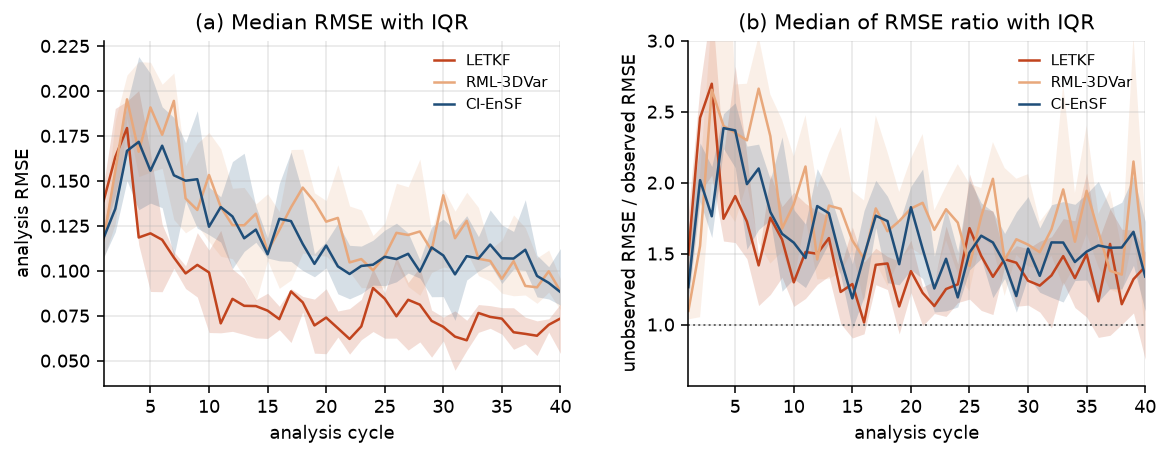

In [12]:
plt.rcParams.update({"font.size":9,"axes.grid":True,"grid.alpha":.3,"legend.frameon":False,
                     "axes.spines.top":False,"axes.spines.right":False,"figure.dpi":140,
                     "savefig.bbox":"tight","lines.linewidth":1.3})
COL = {"LETKF":"#c1441e","RML-3DVar":"#e8a87c","CI-EnSF":"#1f4e79"}
ORD = ["LETKF","RML-3DVar","CI-EnSF"]

def stack(method, col):
    """(n_seeds, N_CYCLES) of one history column, NaN-padded if a seed stopped early."""
    A = np.full((len(RESULTS[method]), N_CYCLES), np.nan)
    for i, z in enumerate(RESULTS[method]):
        h = np.asarray(z["hist"], float)
        if len(h): A[i, :len(h)] = h[:, col]
    return A

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2))
n = np.arange(1, N_CYCLES+1)

# (a) median across realisations with an interquartile envelope.
for m in ORD:
    A = stack(m, 2)                                   # column 2 = RMSE over all components
    q1, q2, q3 = (np.nanpercentile(A, p, axis=0) for p in (25, 50, 75))
    ax[0].fill_between(n, q1, q3, color=COL[m], alpha=.18, lw=0)
    ax[0].plot(n, q2, color=COL[m], label=m)
ax[0].set_xlim(1, N_CYCLES)
ax[0].set_xlabel("analysis cycle"); ax[0].set_ylabel("analysis RMSE")
ax[0].set_title("(a) Median RMSE with IQR")
ax[0].legend(fontsize=7.5, loc="upper right", handlelength=1.4)

# (b) the same construction applied to the unobserved/observed ratio, which says how far
#     observational information travels: the likelihood acts only at observed components, so
#     a ratio that stays of order one means B is carrying information into the rest.
for m in ORD:
    U, O = stack(m, 1), stack(m, 0)          # columns 1 and 0 = unobserved, observed
    Q = U/np.maximum(O, 1e-12)               # ratio per seed per cycle, then across seeds
    q1, q2, q3 = (np.nanpercentile(Q, p, axis=0) for p in (25, 50, 75))
    ax[1].fill_between(n, q1, q3, color=COL[m], alpha=.18, lw=0)
    ax[1].plot(n, q2, color=COL[m], label=m)
ax[1].axhline(1.0, color="0.4", ls=":", lw=1)
ax[1].set_xlim(1, N_CYCLES)
# capped so that the converged behaviour is legible; the spin-up transient of the first few
# cycles runs above this and is clipped rather than compressing the rest of the panel
ax[1].set_ylim(top=3.0)
ax[1].set_xlabel("analysis cycle")
ax[1].set_ylabel("unobserved RMSE / observed RMSE")
ax[1].set_title("(b) Median of RMSE ratio with IQR")
ax[1].legend(fontsize=7.5, loc="upper right", handlelength=1.4)

fig.subplots_adjust(wspace=.28)
fig.savefig("gaussian24h_fig2.pdf"); plt.show()